Enter the mass of the free falling object:80
Enter the constant drag factor:0.42


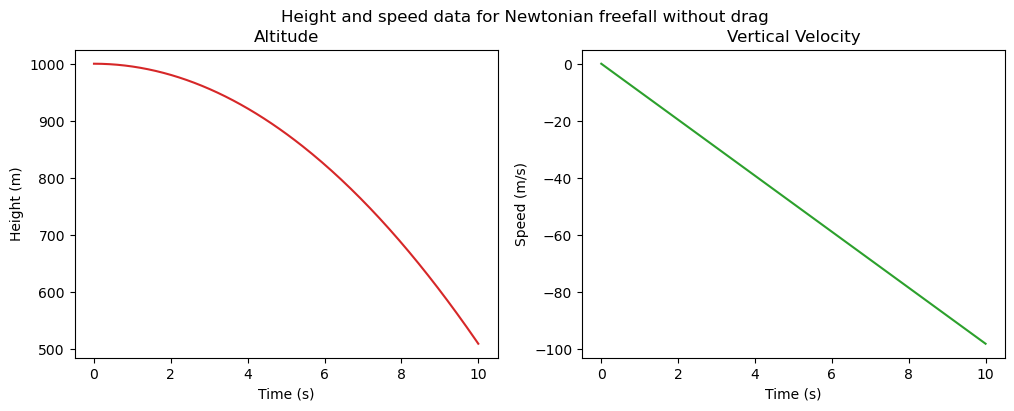

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def y_position_d(y0, m, k, g, t):
    return y0-(m/k)*np.log(np.cosh(np.sqrt(k*g/m)*t))

def y_velocity_d(m, g, k, t):
    return -np.sqrt(m*g/k)*np.tanh(np.sqrt(k*g/m)*t)

def calculate_k(Cd_human, p0, A):
    return (Cd_human*p0*A)/2

g = 9.81 # m/s^2, acceleration
y0 = 1000 # m, initial height
# y0 = float(input('Enter the initial drop height in metres:'))
NumPoints = 200
# m = 104.75 # kg
m = float(input('Enter the mass of the free falling object:'))

p0 = 1.293 # kgm^-3, air density
Cd_human = 1 # drag coefficient
A = 0.7 # cross sectional area of the projectile m^2 (belly down)
# k = (Cd_human*p0*A)/2 # drag constant k for an adult human sky diver
k = float(input('Enter the constant drag factor:')) # drag constant, k

tmin = 0.0  # seconds
tmax = 10.0 # seconds
tvals = np.linspace(tmin,tmax,NumPoints)
yvals = np.zeros(NumPoints)
vyvals = np.zeros(NumPoints)

yvals_d_arr = np.zeros(NumPoints) # v values with drag array
vyvals_d_arr = np.zeros(NumPoints) # vy values with drag array

for i in range(NumPoints):
    vyvals[i] = -g*tvals[i]
    yvals[i] = y0-0.5*g*tvals[i]**2

for i, t in enumerate(tvals):
    yvals_d_arr[i] = y_position_d(y0, m, k, g, t)
    vyvals_d_arr[i] = y_velocity_d(m, g, k, t)
   
fig, (ax1, ax2) = plt.subplots(1, 2,figsize=(12,4))
fig.suptitle('Height and speed data for Newtonian freefall without drag')
ax1.set(xlabel='Time (s)', ylabel='Height (m)', title='Altitude')
ax2.set(xlabel='Time (s)', ylabel='Speed (m/s)', title='Vertical Velocity')
ax1.plot(tvals,yvals,'tab:red')
ax2.plot(tvals,vyvals,'tab:green')
plt.show()

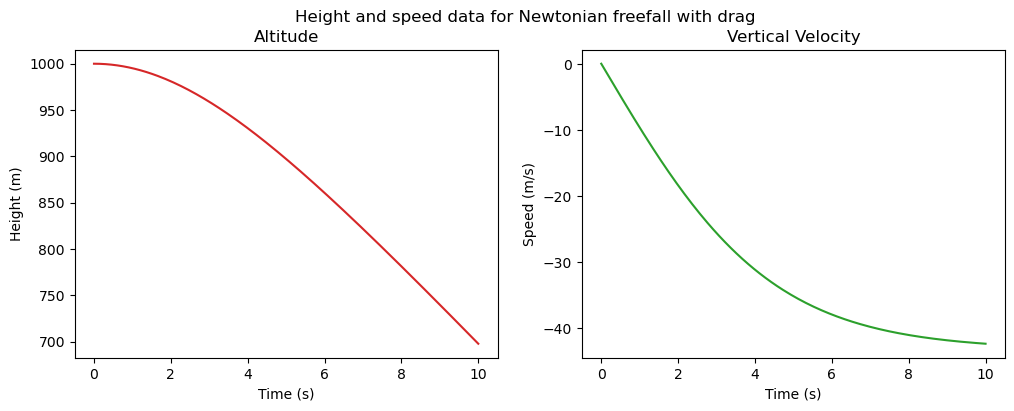

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2,figsize=(12,4))
fig.suptitle('Height and speed data for Newtonian freefall with drag')
ax1.set(xlabel='Time (s)', ylabel='Height (m)', title='Altitude')
ax2.set(xlabel='Time (s)', ylabel='Speed (m/s)', title='Vertical Velocity')
ax1.plot(tvals,yvals_d_arr,'tab:red')
ax2.plot(tvals,vyvals_d_arr,'tab:green')

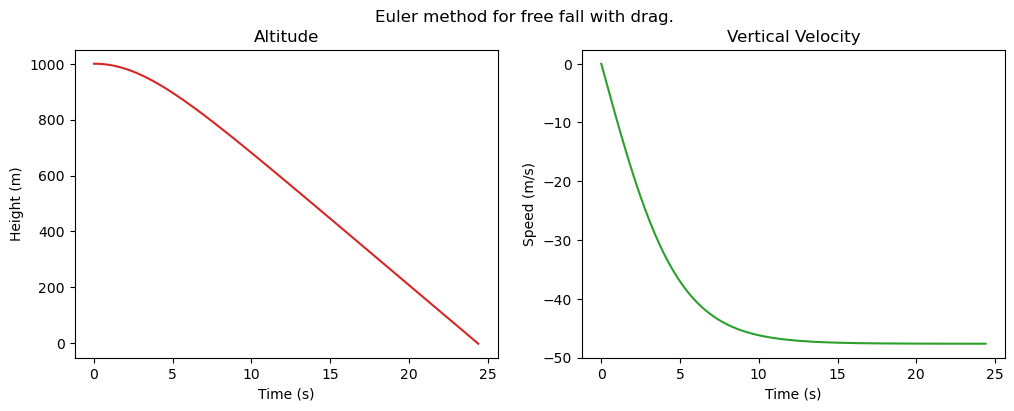

The time taken to land is 24.4 seconds.


In [3]:
def vy5(vyn, dt, g, k, m):
    return vyn-dt*(g+(k/m)*np.abs(vyn)*vyn)
    
def y6(yn, dt, vyn):
    return yn+dt*vyn

def tn7(tn, dt):
    return tn+dt

dt = 0.1 # time step in seconds
NumPoints = 200 # number of elements in the array
vyi = 0 # initial velocity in m/s
yi = 1000 # drop altitude in metres
m = 104.75 # mass in kg

p0 = 1.293 # kgm^-3, air density
Cd_human = 1 # drag coefficient
A = 0.7 # cross sectional area of the projectile m^2 (belly down)
k = (Cd_human*p0*A)/2 # drag constant k for an adult human sky diver

# arrays for values
time = np.array([0])
velocity = np.array([vyi])
altitude = np.array([yi])

i = 0
while i < altitude.size and altitude[i] >= 0:
    vyn = velocity[i]
    velocity = np.append(velocity, vy5(vyn, dt, g, k, m))
    yn = altitude[i]
    altitude = np.append(altitude, y6(yn, dt, vyn))
    tn = time[i]
    time = np.append(time, tn7(tn, dt))
    i += 1

fig, (ax1, ax2) = plt.subplots(1, 2,figsize=(12,4))
fig.suptitle('Euler method for free fall with drag.')
ax1.set(xlabel='Time (s)', ylabel='Height (m)', title='Altitude')
ax2.set(xlabel='Time (s)', ylabel='Speed (m/s)', title='Vertical Velocity')
ax1.plot(time,altitude,'tab:red')
ax2.plot(time,velocity,'tab:green')
plt.show()

print(f'The time taken to land is {round(time[-1], 2)} seconds.')

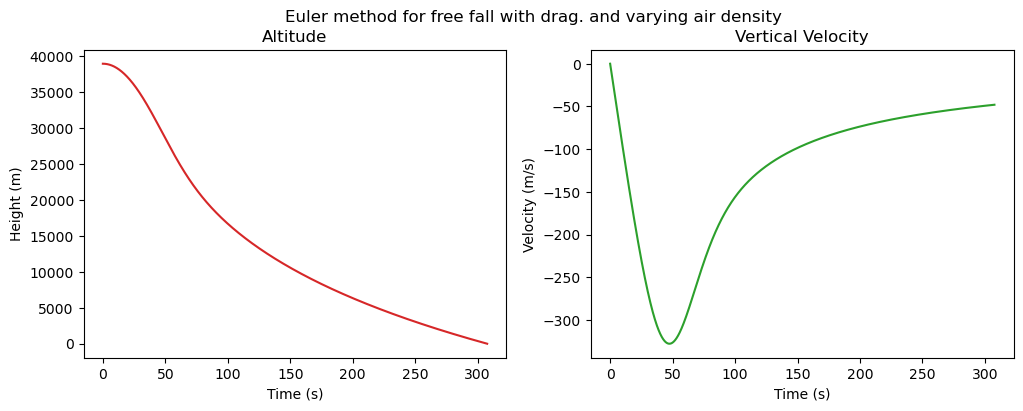

The time taken to land is 307.6 seconds.


In [8]:
def calculate_p_air(p0, y, h): # function to calculate values for air density 
    return p0*np.exp(-y/h)

NumPoints = 200 # number of elements in the array
vyi = 0 # initial velocity in m/s
m = 104.75 # mass in kg

p0 = 1.293 # kgm^-3, air density
Cd_human = 1.0 # drag coefficient
A = 0.7 # cross sectional area of the projectile m^2 (belly down)

h = 7640 # scale height in km^2
y0 = 38969.4 # drop altitude in m
vyi = 0 # initial velocity in m/s
dt = 0.1 # time step in seconds
p0 = 1.293 # kgm^-3, air density
time = np.array([0])
velocity = np.array([vyi])
altitude = np.array([y0])
i = 0

while i < altitude.size and altitude[i] >= 0:
    p_air = calculate_p_air(p0, yn, h)
    kn = calculate_k(Cd_human, p_air, A)
    vyn = velocity[i]
    velocity = np.append(velocity, vy5(vyn, dt, g, kn, m))
    yn = altitude[i]
    altitude = np.append(altitude, y6(yn, dt, vyn))
    tn = time[i]
    time = np.append(time, tn7(tn, dt))
    i += 1

fig, (ax1, ax2) = plt.subplots(1, 2,figsize=(12,4))
fig.suptitle('Euler method for free fall with drag. and varying air density')
ax1.set(xlabel='Time (s)', ylabel='Height (m)', title='Altitude')
ax2.set(xlabel='Time (s)', ylabel='Velocity (m/s)', title='Vertical Velocity')
ax1.plot(time,altitude,'tab:red')
ax2.plot(time,velocity,'tab:green')
plt.show()
print(f'The time taken to land is {round(time[-1], 2)} seconds.')